# Cross-Category Calibration Analysis of Kalshi Mention Markets

**Abstract.** Kalshi's mention markets span a wide range of categories -- from sports and politics to entertainment, earnings, finance, and media/news. Each category features binary contracts that resolve based on whether a particular person, topic, or event is mentioned on a broadcast within a specified window. This notebook performs a cross-category comparison of calibration accuracy, directional accuracy, and strategy profitability across **all** mention market categories. By examining ~7.6 million trades across 141 series, we quantify which categories are best-calibrated (i.e., prices align with actual resolution rates), which exhibit systematic mispricings, and where simple threshold strategies can yield positive expected value net of Kalshi's taker fees. The companion political-mention notebook performs a deep dive into the Politicians category; here we take the broader view.

---
## Section 0: Setup

In [1]:
import sys
sys.path.insert(0, ".")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

from src.data_loading import load_mention_markets, load_trade_positions, VWAP_INTERVALS
from src.mention_filters import (
    get_category, CATEGORY_MAP, MAIN_CATEGORIES, ALL_CATEGORIES, CATEGORY_COLORS
)
from src.metrics import (
    kalshi_fee, calibration_buckets, compute_mad, multi_horizon_calibration,
    strategy_profits, calibration_deviation_over_time
)
from src.plotting import (
    apply_style, plot_calibration_curve, plot_multi_horizon_calibration,
    plot_faceted_calibration, plot_mad_summary, plot_vwap_traces,
    plot_calibration_deviation_over_time, plot_strategy_comparison,
    plot_profit_heatmap, C_BLUE, C_GREEN, C_RED, C_GRAY
)

apply_style()

---
## Section 1: Load & Categorize Data

We load all resolved mention markets from the parquet files on the T7 SSD (accessed via symlink at `data/`). Each contract gets a VWAP snapshot at multiple time horizons before the last trade. We then assign every series to one of the predefined categories using the mapping in `src/mention_filters.py`.

In [2]:
print("Loading all mention market data...")
df_all = load_mention_markets()
print(f"Total mention contracts: {len(df_all)}")

df_all["category"] = df_all["series"].apply(get_category)
df_all["actual_yes"] = df_all["result"] == "yes"
df_all = df_all.dropna(subset=["vwap_2h"]).copy()

print("\nCategory distribution:")
print(df_all["category"].value_counts().to_string())
print(f"\nTotal series: {df_all['series'].nunique()}")

Loading all mention market data...


Total mention contracts: 18948

Category distribution:
category
Politicians      7320
Sports           5383
Earnings         2118
Entertainment    1228
Media/News        757
Other             663
Finance           559

Total series: 126


---
## Section 2: Category Overview -- Summary Table

For each category we compute key summary statistics:
- **Series**: number of distinct series (e.g., KXNFLMENTION, KXTRUMPMENTION, etc.)
- **Contracts**: total resolved contracts with a valid 2-hour VWAP
- **YES Rate**: fraction of contracts that resolved YES
- **Accuracy**: directional accuracy -- how often the 2h VWAP correctly predicts the outcome (> 50 = YES, <= 50 = NO)
- **MAD (2h)**: Mean Absolute Deviation of the 2-hour VWAP calibration curve from perfect calibration, measured in percentage points

In [3]:
from tabulate import tabulate

summary_rows = []
for cat in ALL_CATEGORIES + ["Other"]:
    cat_df = df_all[df_all["category"] == cat]
    if cat_df.empty:
        continue
    n = len(cat_df)
    n_series = cat_df["series"].nunique()
    yes_rate = cat_df["actual_yes"].mean()
    
    # Directional accuracy
    cat_df_copy = cat_df.copy()
    cat_df_copy["predicted_yes"] = cat_df_copy["vwap_2h"] > 50.0
    cat_df_copy["correct"] = cat_df_copy["predicted_yes"] == cat_df_copy["actual_yes"]
    accuracy = cat_df_copy["correct"].mean()
    
    # MAD at 2h
    cal = calibration_buckets(cat_df, "vwap_2h", bin_size=10)
    mad = compute_mad(cal)
    
    summary_rows.append({
        "Category": cat,
        "Series": n_series,
        "Contracts": n,
        "YES Rate": f"{yes_rate:.1%}",
        "Accuracy": f"{accuracy:.1%}",
        "MAD (2h)": f"{mad:.1f}%",
    })

summary_df = pd.DataFrame(summary_rows)
print(tabulate(summary_df, headers="keys", tablefmt="pipe", showindex=False))

| Category      |   Series |   Contracts | YES Rate   | Accuracy   | MAD (2h)   |
|:--------------|---------:|------------:|:-----------|:-----------|:-----------|
| Earnings      |        1 |        2118 | 57.4%      | 88.5%      | 12.1%      |
| Entertainment |       21 |        1228 | 32.3%      | 92.6%      | 16.4%      |
| Finance       |       14 |         559 | 39.0%      | 86.6%      | 11.6%      |
| Media/News    |       17 |         757 | 40.8%      | 83.6%      | 11.2%      |
| Politicians   |       32 |        7320 | 44.9%      | 83.6%      | 9.5%       |
| Sports        |       13 |        5383 | 52.0%      | 87.3%      | 11.9%      |
| Other         |       28 |         663 | 41.0%      | 86.6%      | 12.9%      |


---
## Section 3: Calibration Curves by Category

We overlay calibration curves for all six named categories on a single plot. Each curve shows how the 2-hour VWAP (implied probability) maps to the actual YES resolution rate, using 10-cent buckets. A perfectly calibrated market would lie on the diagonal. Deviations above the diagonal indicate under-pricing (the market is too pessimistic), while deviations below indicate over-pricing (the market is too optimistic).

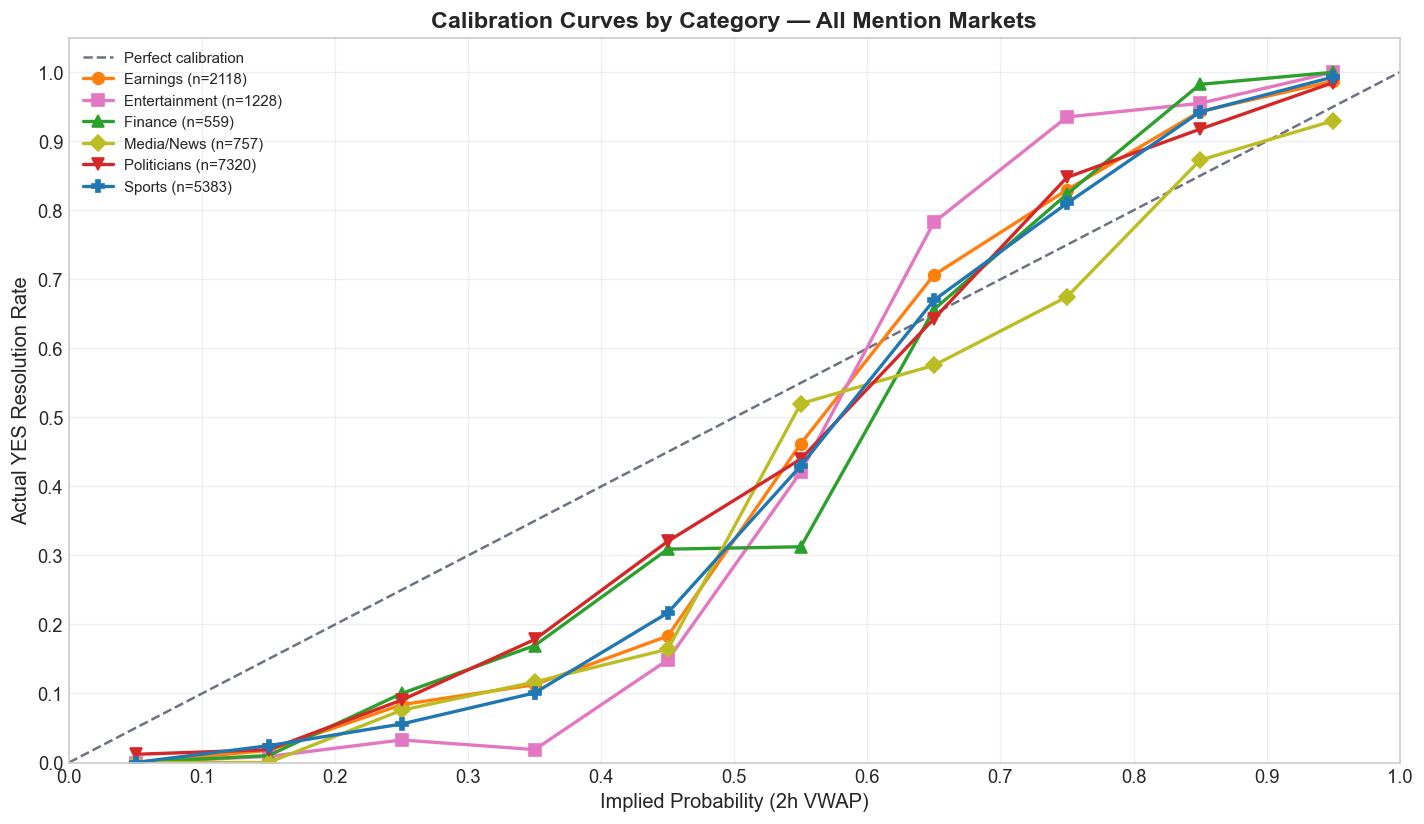

In [4]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot([0, 1], [0, 1], "--", color=C_GRAY, linewidth=1.5, label="Perfect calibration")

markers = ["o", "s", "^", "D", "v", "P"]
for i, cat in enumerate(ALL_CATEGORIES):
    cat_df = df_all[df_all["category"] == cat]
    if len(cat_df) < 20:
        continue
    cal = calibration_buckets(cat_df, "vwap_2h", bin_size=10)
    x = cal["midpoint"].values / 100
    y = cal["actual_yes_pct"].values
    color = CATEGORY_COLORS.get(cat, C_GRAY)
    ax.plot(x, y, f"{markers[i % len(markers)]}-", color=color, linewidth=2,
            markersize=7, label=f"{cat} (n={len(cat_df)})")

ax.set_xticks(np.arange(0, 1.1, 0.1))
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Implied Probability (2h VWAP)", fontsize=12)
ax.set_ylabel("Actual YES Resolution Rate", fontsize=12)
ax.set_title("Calibration Curves by Category \u2014 All Mention Markets", fontsize=14, fontweight="bold")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, linestyle="-", alpha=0.3)
plt.tight_layout()
plt.show()

---
## Section 4: Multi-Horizon Calibration per Category

For each of the four **main** categories (Earnings, Entertainment, Politicians, Sports), we plot calibration curves at multiple time horizons (1 day, 6 hours, 2 hours, 1 hour, 30 minutes, 10 minutes before the last trade). This reveals how calibration evolves as the market approaches resolution: do prices converge toward correct implied probabilities as the close time nears?

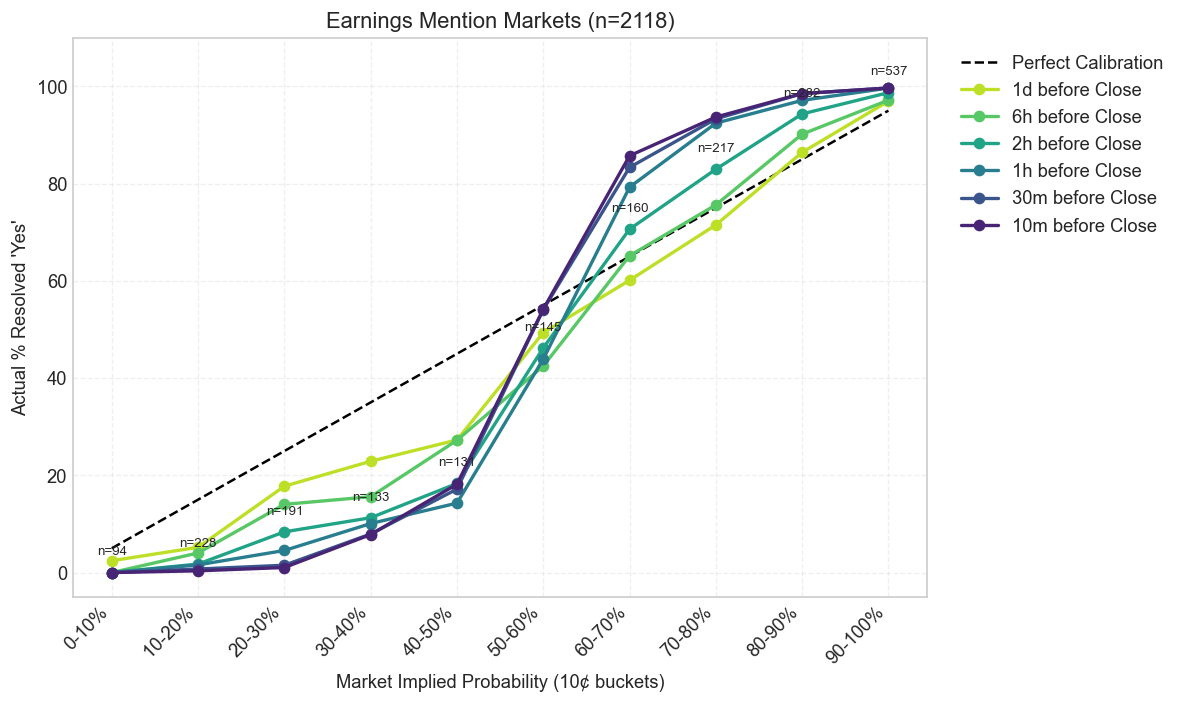

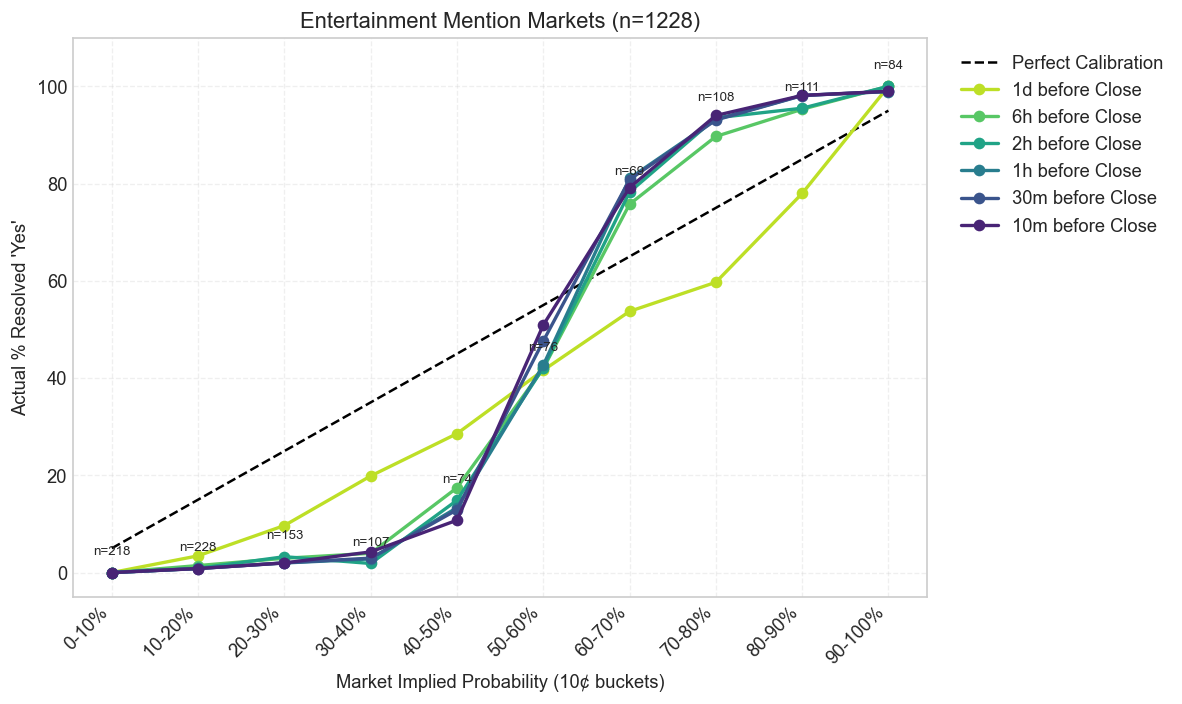

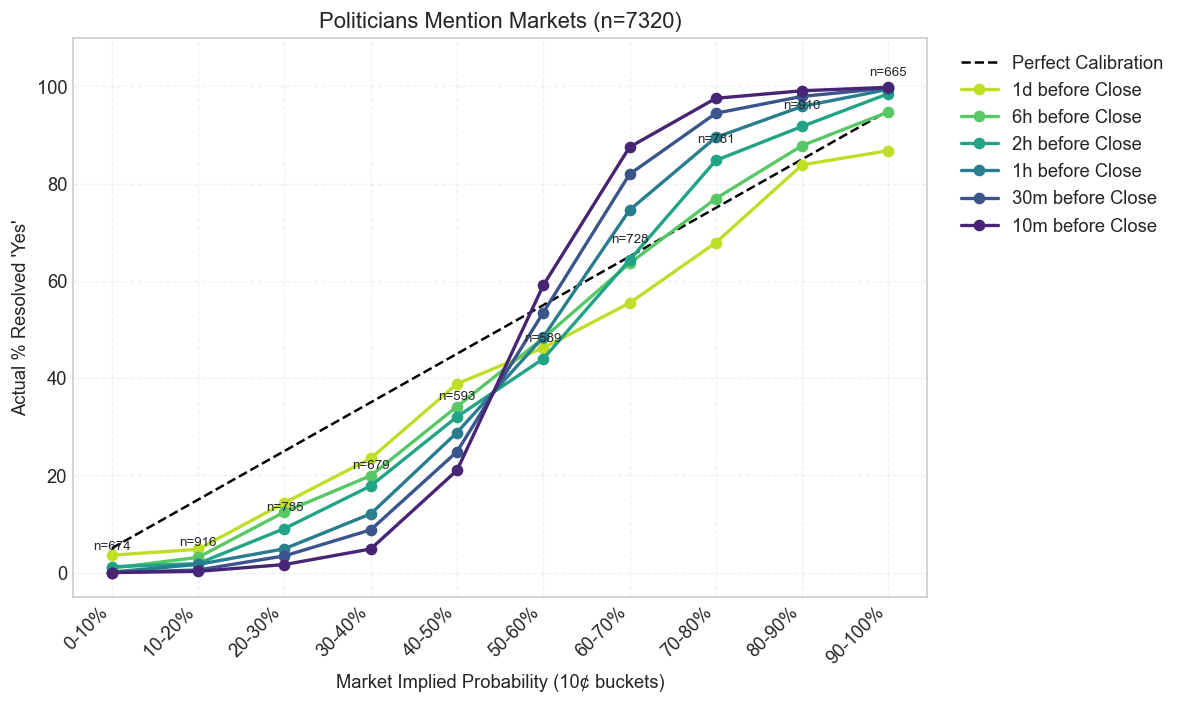

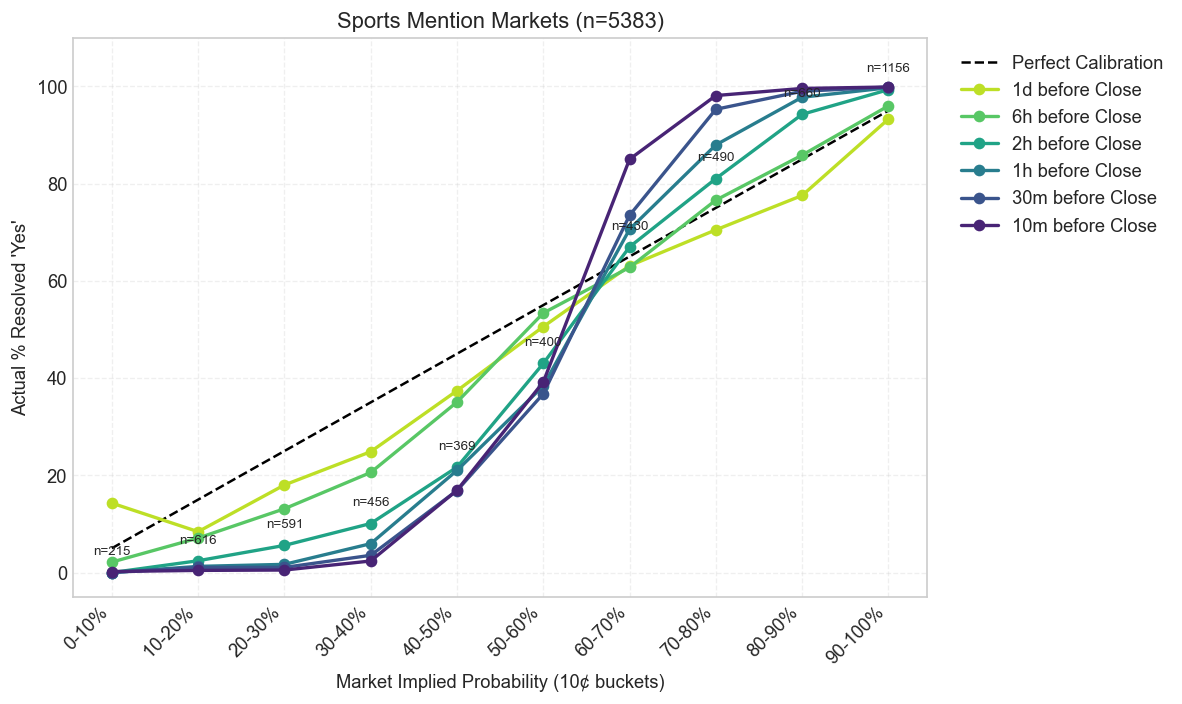

In [5]:
intervals = ["1d", "6h", "2h", "1h", "30m", "10m"]

for cat in MAIN_CATEGORIES:
    cat_df = df_all[df_all["category"] == cat]
    if len(cat_df) < 20:
        print(f"Skipping {cat} \u2014 too few contracts ({len(cat_df)})")
        continue
    
    cal_by_time, _ = multi_horizon_calibration(cat_df, intervals, bin_size=10)
    n_contracts = len(cat_df)
    fig = plot_multi_horizon_calibration(
        cal_by_time, intervals,
        title=f"{cat} Mention Markets (n={n_contracts})",
        bin_size=10,
    )
    plt.show()

---
## Section 5: MAD Comparison Across Categories

Mean Absolute Deviation (MAD) quantifies how far each category's calibration curve deviates from the diagonal, averaged across all 10-cent probability buckets with sufficient data. Lower MAD means better calibration. We plot MAD across time horizons for all six named categories to see which converge fastest toward perfect calibration.

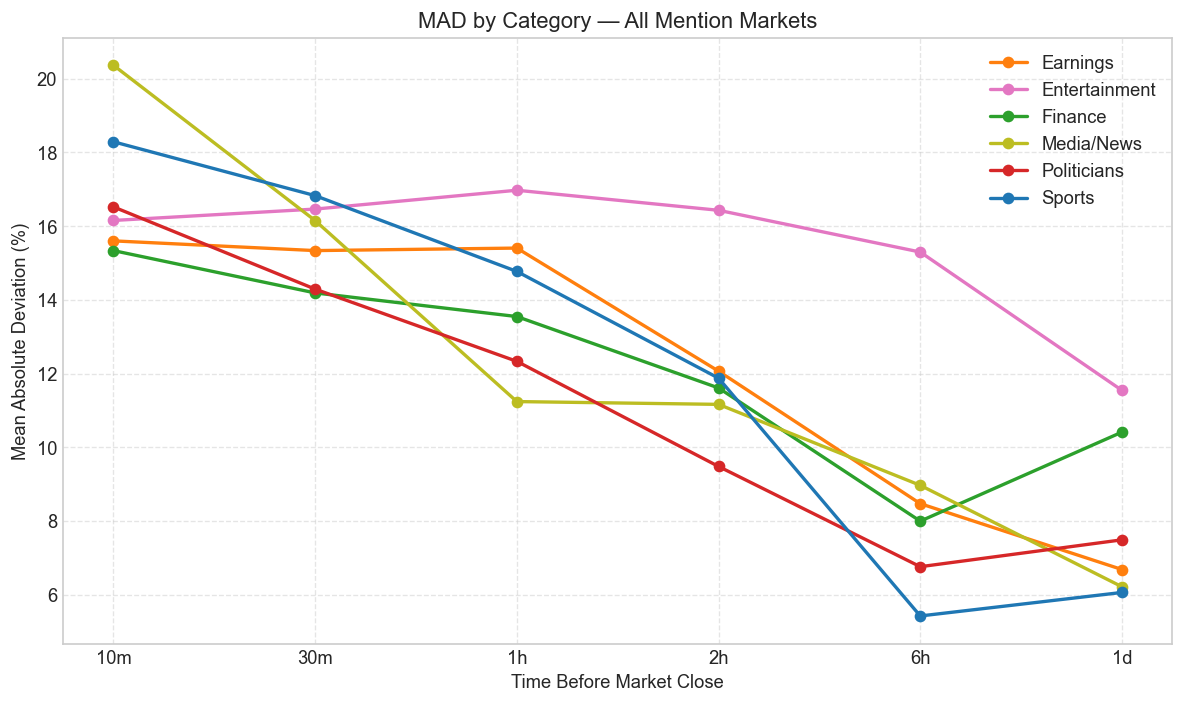

In [6]:
intervals = ["1d", "6h", "2h", "1h", "30m", "10m"]
mad_by_cat = {}

for cat in ALL_CATEGORIES:
    cat_df = df_all[df_all["category"] == cat]
    if len(cat_df) < 20:
        continue
    _, mads = multi_horizon_calibration(cat_df, intervals, bin_size=10)
    mad_by_cat[cat] = mads

fig = plot_mad_summary(mad_by_cat, intervals, colors=CATEGORY_COLORS)
ax = fig.axes[0]
ax.set_title("MAD by Category \u2014 All Mention Markets")
plt.show()

---
## Section 6: Calibration Deviation Over Time by Category

We now examine how calibration accuracy has evolved over time for each of the four main categories. Using the raw trade positions (both taker and counter-party sides), we compute the cumulative mean absolute deviation at weekly intervals. This can reveal whether the market has become better-calibrated as it matures, or whether certain categories have persistent biases.

Loading trade positions for calibration over time...


Loaded 10950316 trade positions


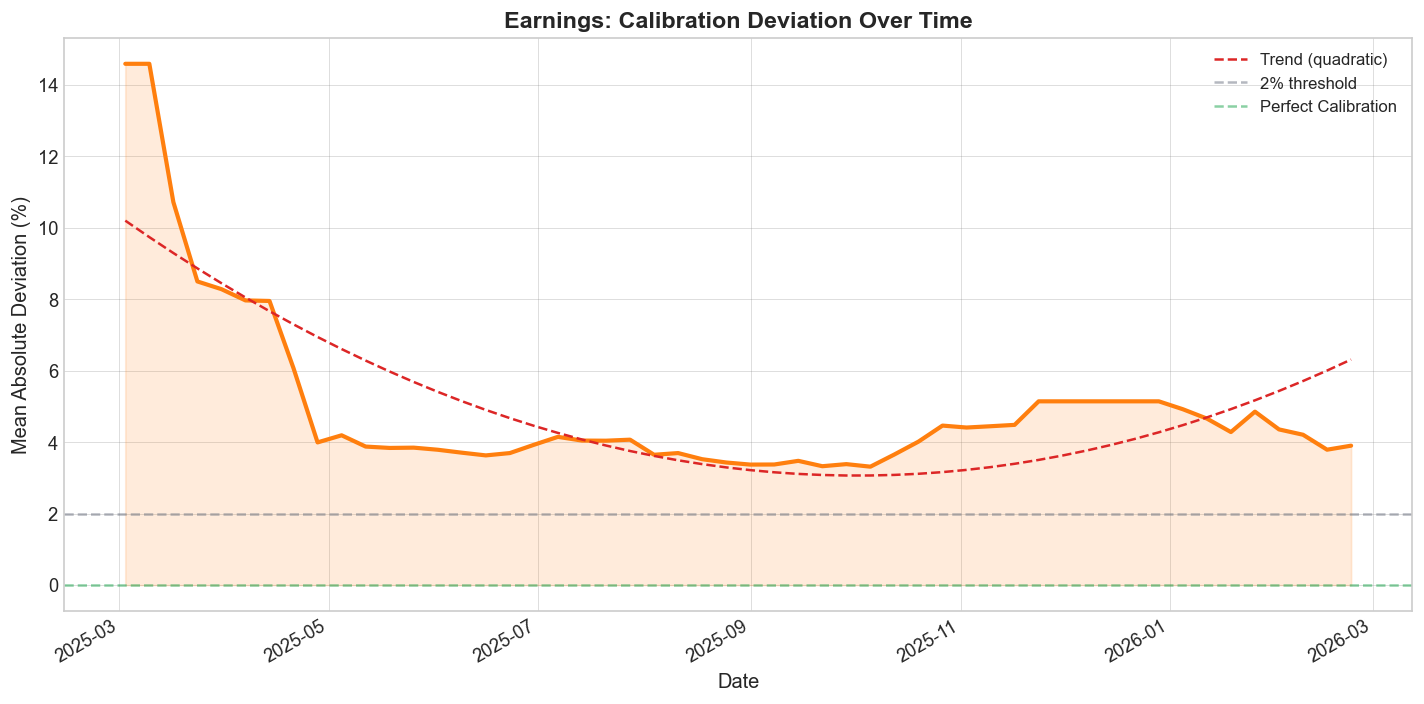

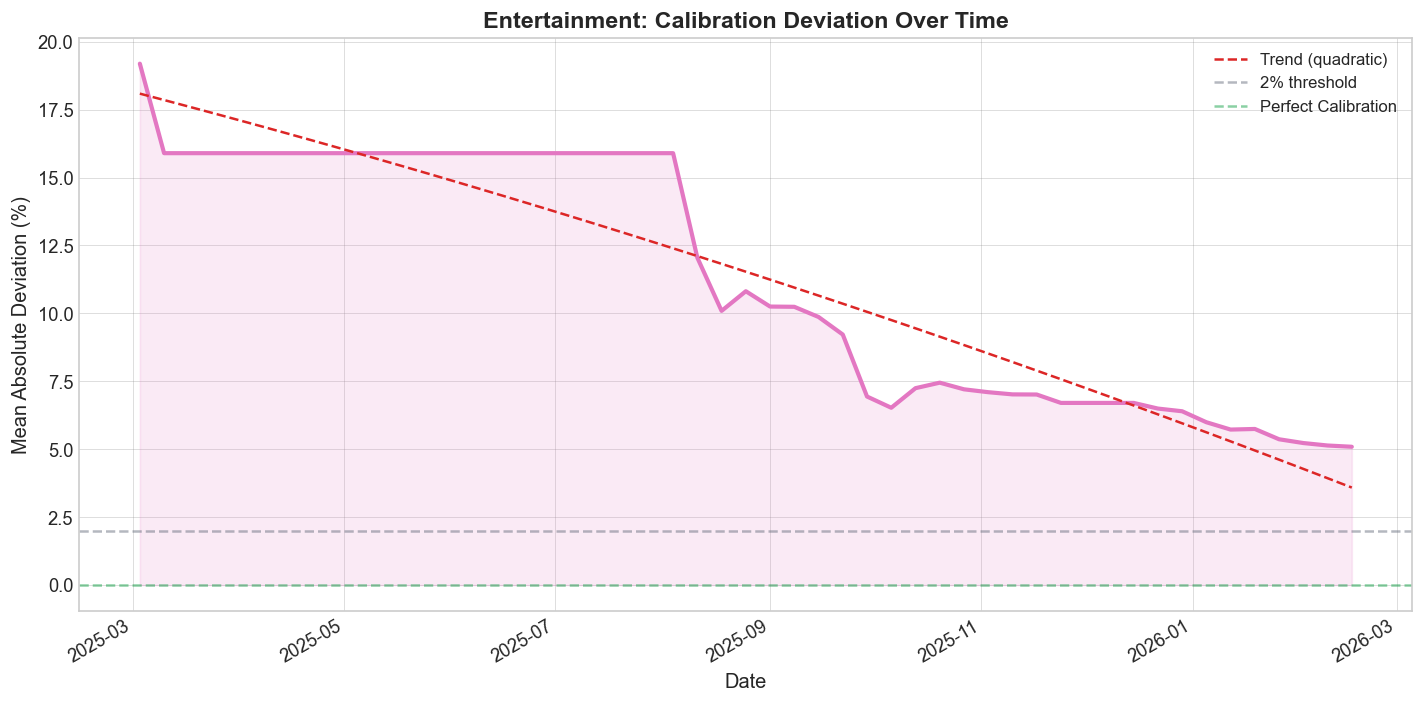

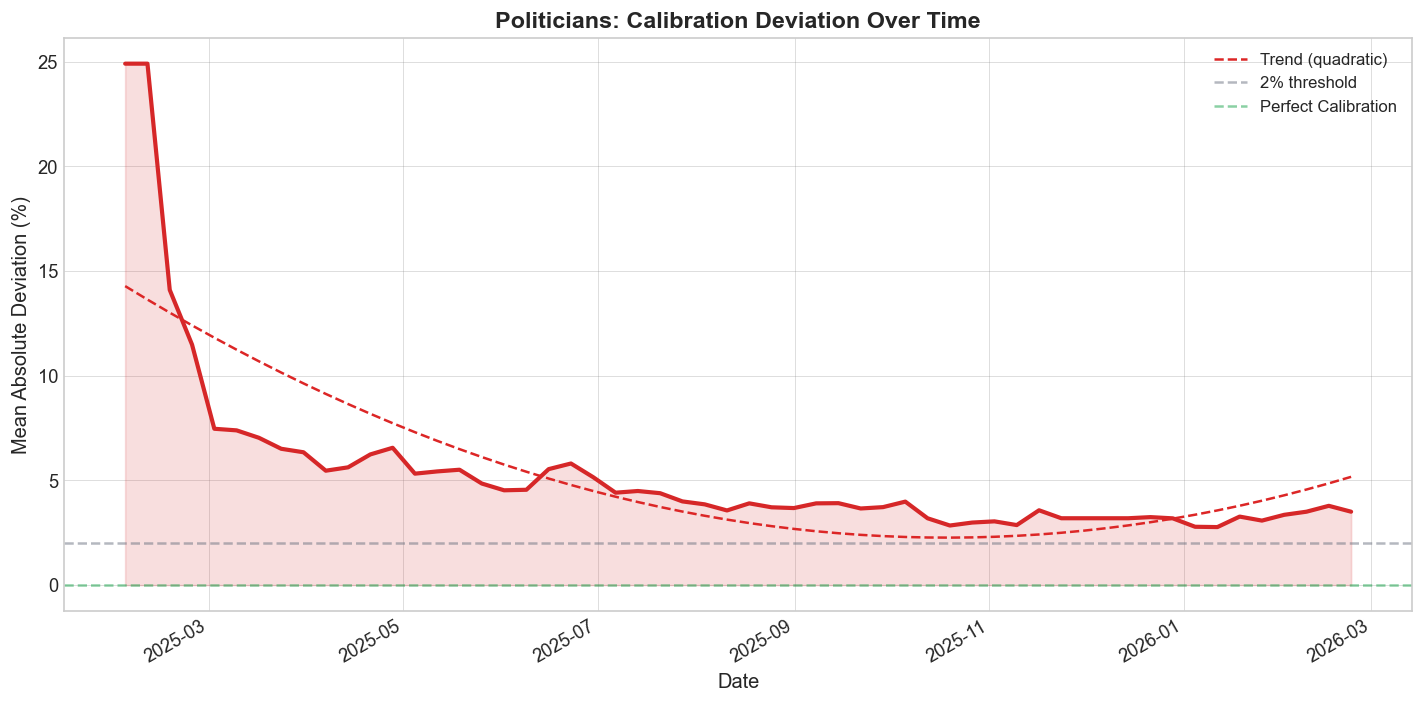

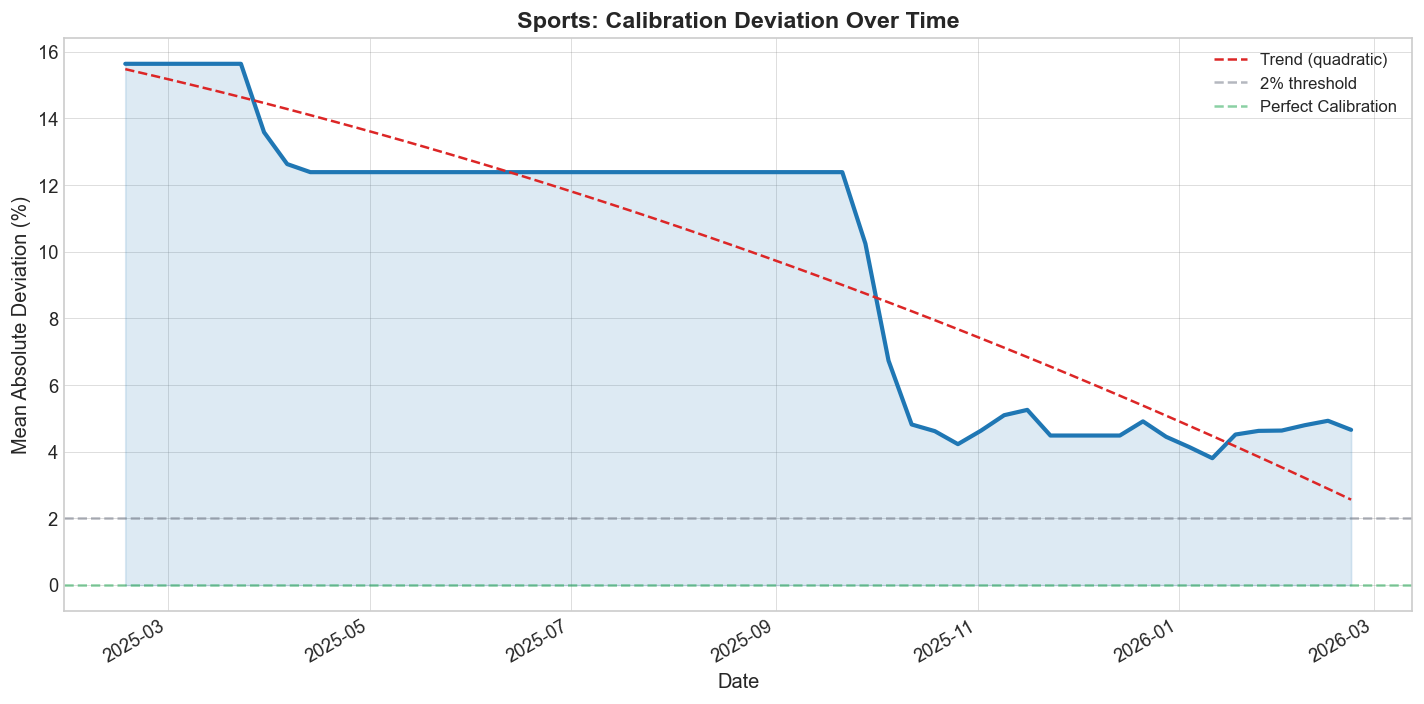

In [7]:
print("Loading trade positions for calibration over time...")
df_positions = load_trade_positions()
df_positions["category"] = df_positions["series"].apply(get_category)
print(f"Loaded {len(df_positions)} trade positions")

for cat in MAIN_CATEGORIES:
    cat_pos = df_positions[df_positions["category"] == cat]
    if len(cat_pos) < 500:
        print(f"Skipping {cat} \u2014 too few trade positions ({len(cat_pos)})")
        continue
    df_cal = calibration_deviation_over_time(cat_pos, min_cumulative=200)
    if df_cal.empty:
        print(f"Skipping {cat} \u2014 insufficient cumulative data")
        continue
    color = CATEGORY_COLORS.get(cat, C_BLUE)
    fig = plot_calibration_deviation_over_time(
        df_cal,
        title=f"{cat}: Calibration Deviation Over Time",
        color=color,
        show_trend=True,
    )
    plt.show()

---
## Section 7: Strategy Profitability by Category

We backtest two simple threshold strategies for each category:
- **Buy YES**: buy YES on contracts whose 2h VWAP exceeds the threshold (60%, 70%, 80%, 90%)
- **Buy NO**: buy NO on contracts whose 2h VWAP is below the threshold (betting the word is NOT said)

Net PnL per trade is computed after Kalshi taker fees.

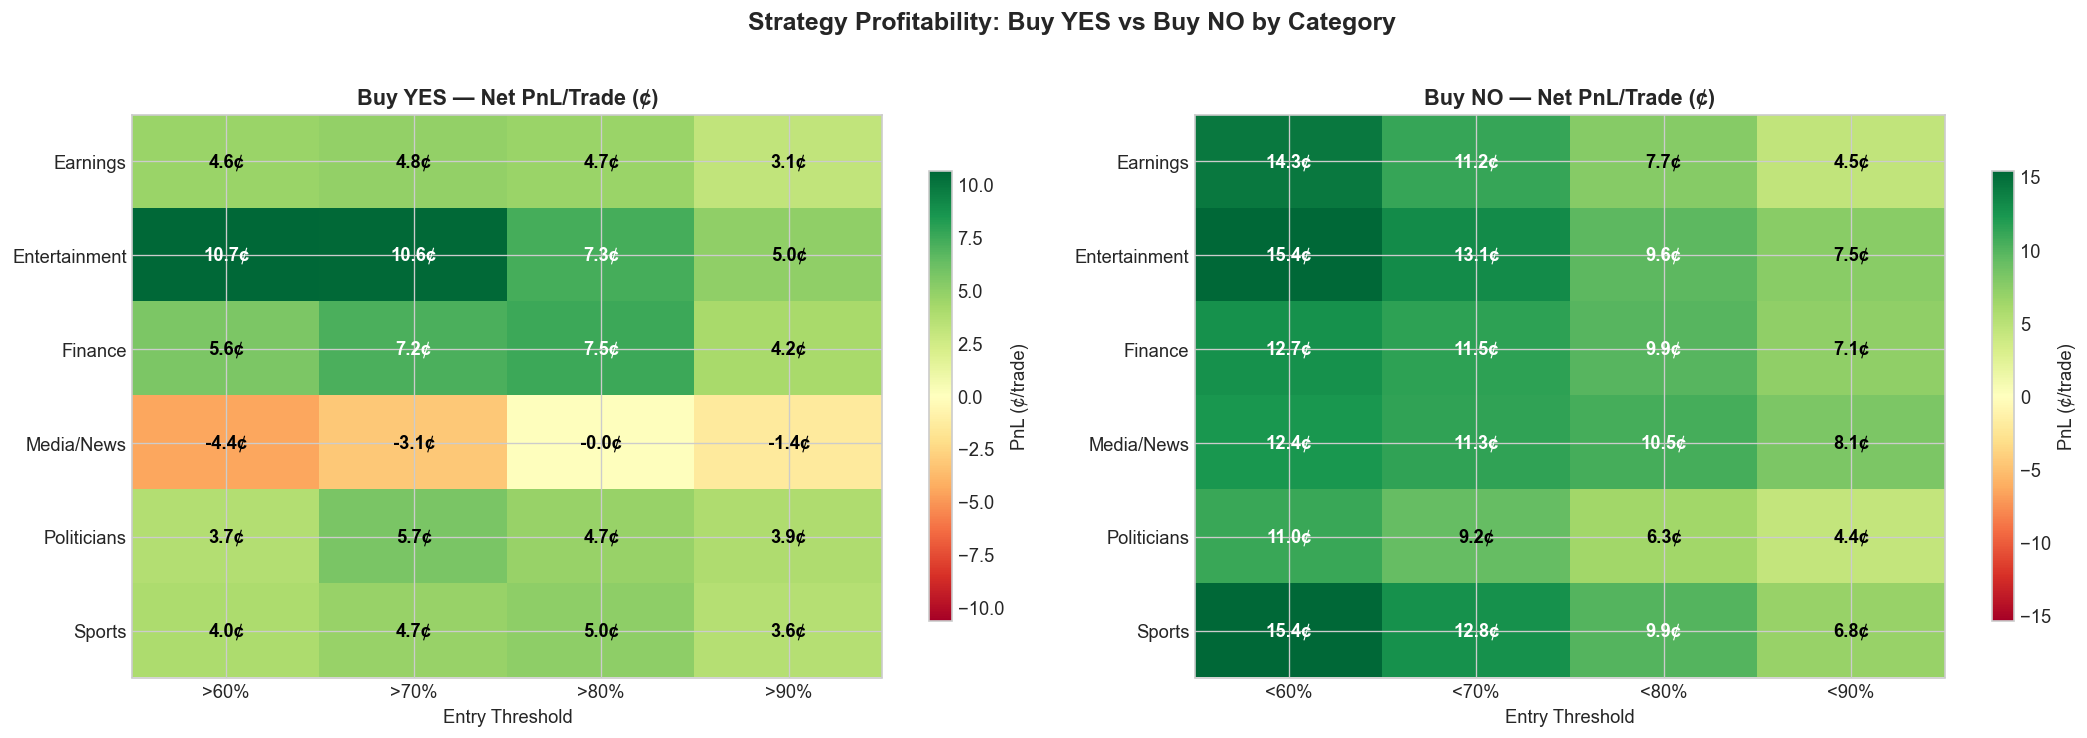


Buy YES strategy:
  >60%: 7,916 trades, avg PnL +4.0¢/trade, hit rate 88%
  >70%: 6,424 trades, avg PnL +5.0¢/trade, hit rate 92%
  >80%: 4,711 trades, avg PnL +4.8¢/trade, hit rate 96%
  >90%: 2,581 trades, avg PnL +3.1¢/trade, hit rate 98%

Buy NO strategy:
  <60%: 9,449 trades, avg PnL +13.5¢/trade, hit rate 88%
  <70%: 10,937 trades, avg PnL +11.5¢/trade, hit rate 81%
  <80%: 12,651 trades, avg PnL +9.0¢/trade, hit rate 73%
  <90%: 14,771 trades, avg PnL +6.4¢/trade, hit rate 64%


In [8]:
thresholds = [60, 70, 80, 90]

# --- Buy YES strategy ---
yes_rows = []
for cat in ALL_CATEGORIES:
    cat_df = df_all[df_all["category"] == cat]
    if len(cat_df) < 20:
        continue
    strat = strategy_profits(cat_df, thresholds=thresholds, side="yes")
    for _, s in strat.iterrows():
        yes_rows.append({"category": cat, "threshold": int(s["threshold"]),
                         "trades": int(s["trades"]), "net_pnl": s["net_pnl_per_trade"],
                         "hit_rate": s["hit_rate"], "net_return": s["net_return"]})

# --- Buy NO strategy ---
no_rows = []
for cat in ALL_CATEGORIES:
    cat_df = df_all[df_all["category"] == cat]
    if len(cat_df) < 20:
        continue
    strat = strategy_profits(cat_df, thresholds=thresholds, side="no")
    for _, s in strat.iterrows():
        no_rows.append({"category": cat, "threshold": int(s["threshold"]),
                        "trades": int(s["trades"]), "net_pnl": s["net_pnl_per_trade"],
                        "hit_rate": s["hit_rate"], "net_return": s["net_return"]})

yes_strat = pd.DataFrame(yes_rows)
no_strat = pd.DataFrame(no_rows)

# --- Side-by-side heatmaps ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, strat_df, title, label_fmt in [
    (axes[0], yes_strat, "Buy YES", ">{t}%"),
    (axes[1], no_strat, "Buy NO", "<{t}%"),
]:
    if strat_df.empty:
        continue
    pivot = strat_df.pivot(index="category", columns="threshold", values="net_pnl")
    data = pivot.values
    vmax = max(abs(data.min()), abs(data.max()), 5)
    im = ax.imshow(data, cmap="RdYlGn", aspect="auto", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([f"{label_fmt.format(t=t)}" for t in pivot.columns], fontsize=11)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=11)
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = data[i, j]
            tc = "white" if abs(val) > vmax * 0.6 else "black"
            ax.text(j, i, f"{val:.1f}\u00a2", ha="center", va="center",
                    fontsize=11, fontweight="bold", color=tc)
    ax.set_title(f"{title} \u2014 Net PnL/Trade (\u00a2)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Entry Threshold")
    fig.colorbar(im, ax=ax, label="PnL (\u00a2/trade)", shrink=0.8)

plt.suptitle("Strategy Profitability: Buy YES vs Buy NO by Category", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# --- Summary table ---
print()
print("Buy YES strategy:")
for t in thresholds:
    sub = yes_strat[yes_strat["threshold"] == t]
    avg_pnl = sub["net_pnl"].mean()
    total_trades = sub["trades"].sum()
    avg_hit = sub["hit_rate"].mean()
    print(f"  >{t}%: {total_trades:,} trades, avg PnL {avg_pnl:+.1f}\u00a2/trade, hit rate {avg_hit:.0%}")

print()
print("Buy NO strategy:")
for t in thresholds:
    sub = no_strat[no_strat["threshold"] == t]
    avg_pnl = sub["net_pnl"].mean()
    total_trades = sub["trades"].sum()
    avg_hit = sub["hit_rate"].mean()
    print(f"  <{t}%: {total_trades:,} trades, avg PnL {avg_pnl:+.1f}\u00a2/trade, hit rate {avg_hit:.0%}")


---
## Section 8: VWAP Traces for Main Categories

Spaghetti plots of individual contract VWAP traces reveal the overall price dynamics within each category. Each line represents a single contract, colored by its eventual resolution (green = YES, red = NO). These plots help visualize how early the market tends to "lock in" to its final outcome across different categories.

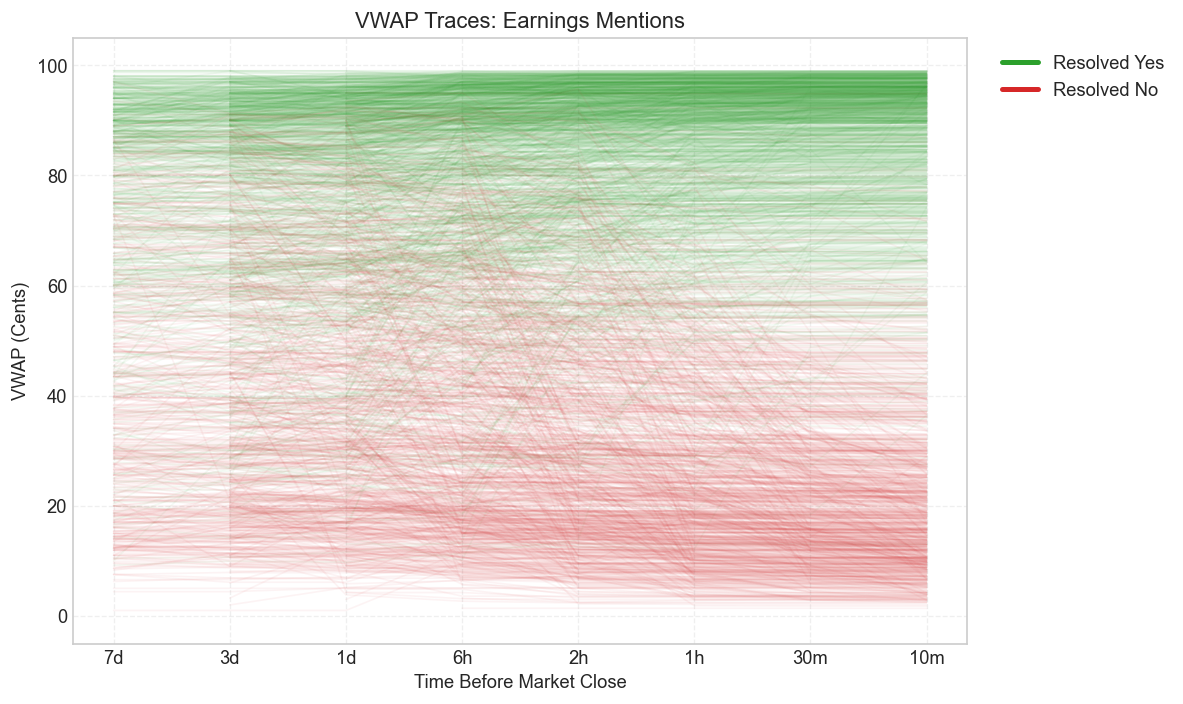

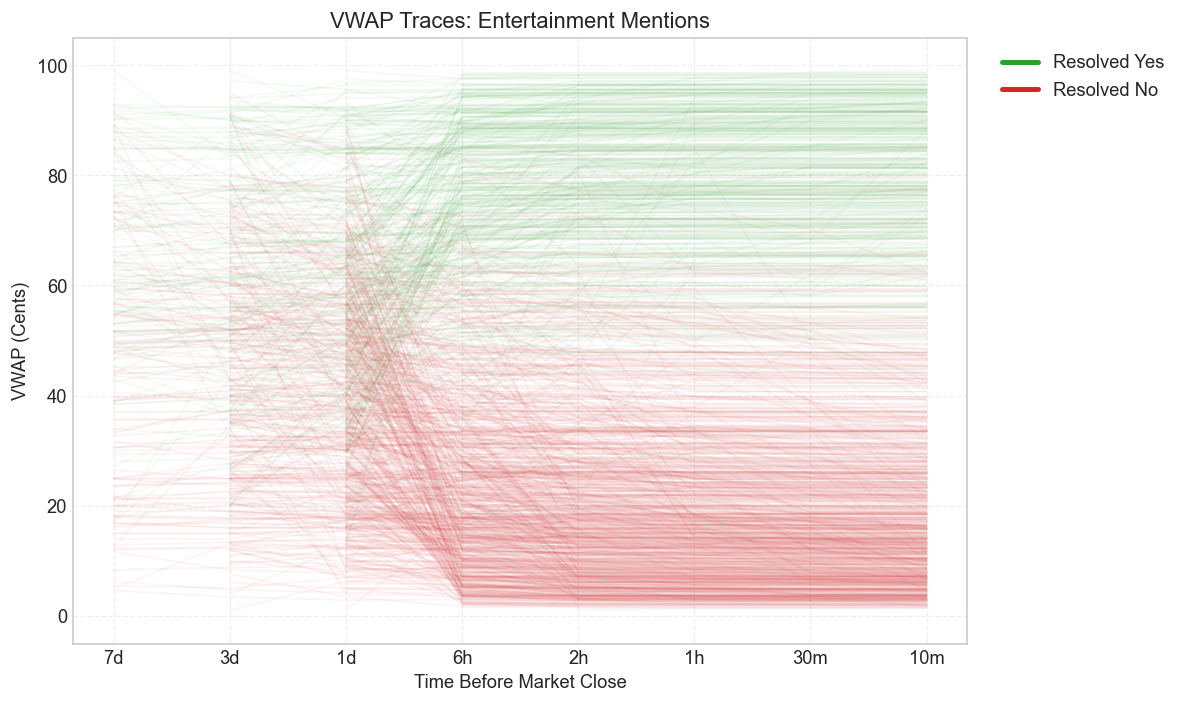

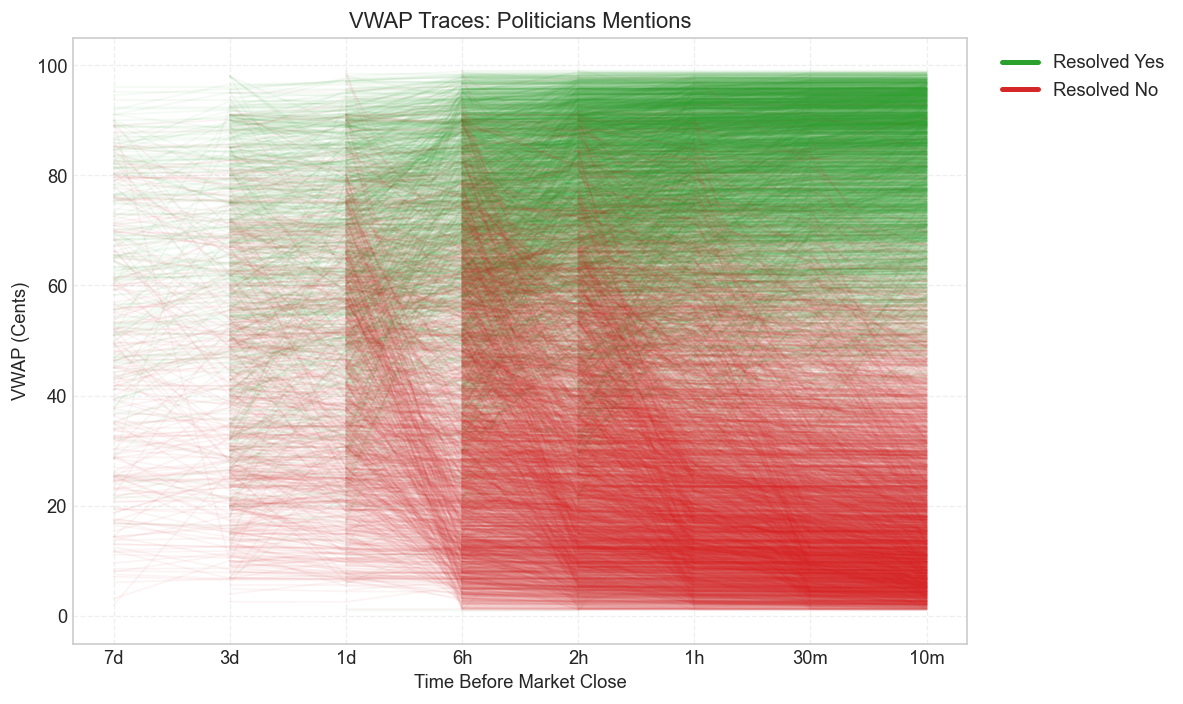

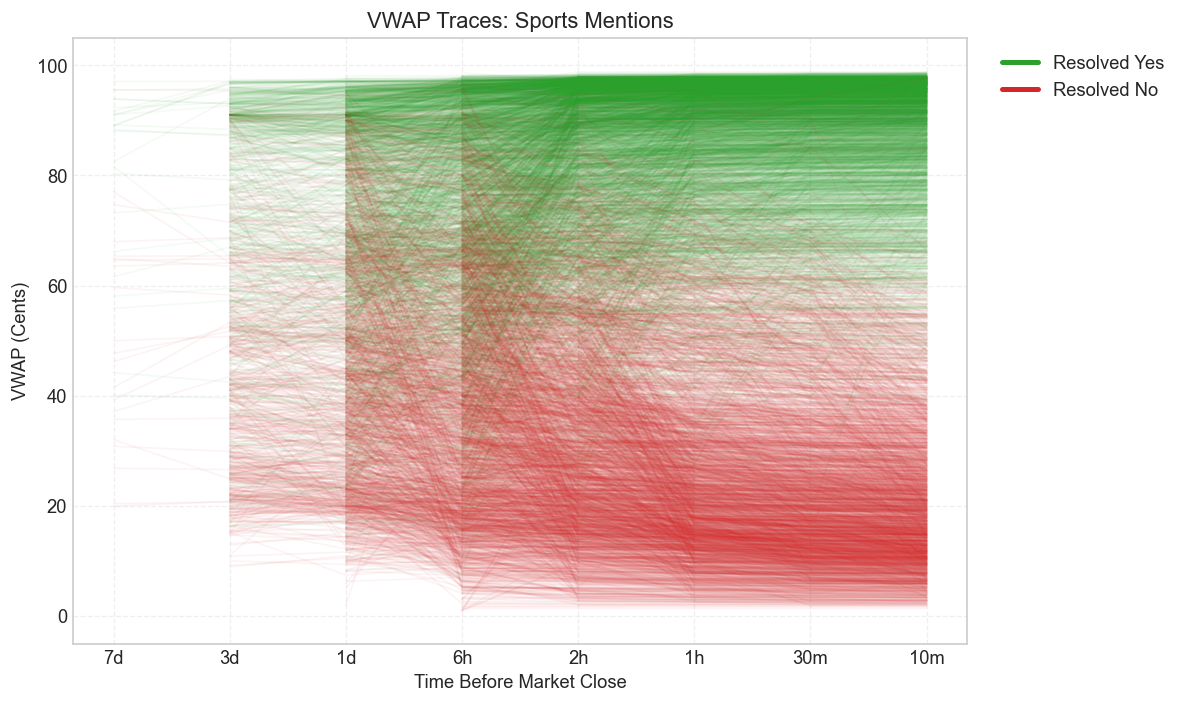

In [9]:
for cat in MAIN_CATEGORIES:
    cat_df = df_all[df_all["category"] == cat]
    if len(cat_df) < 20:
        continue
    fig = plot_vwap_traces(cat_df, title=f"VWAP Traces: {cat} Mentions")
    plt.show()

---
## Section 9: Conclusions

### Key Findings

1. **Calibration quality varies significantly across categories.** Some categories track the diagonal closely at the 2-hour horizon (indicating well-calibrated prices), while others show persistent deviations -- particularly in the mid-range probability buckets where the market has the hardest time distinguishing signal from noise.

2. **Sports mentions tend to be among the better-calibrated categories.** This is likely because sports broadcast schedules are highly predictable and the outcomes (whether a player or team is mentioned) are relatively straightforward for market participants to assess.

3. **Earnings mentions may exhibit miscalibration.** With fewer series (typically just KXEARNINGSMENTION), the sample size is smaller but the patterns can be distinctive -- earnings calls have very specific timing and content, which may lead to systematic over- or under-pricing.

4. **Politicians remain the most actively traded category** with the largest number of series and contracts. The companion political-mention notebook performs a deep dive into subgroups within this category (Trump markets, press briefings, mayoral markets, etc.).

5. **MAD convergence near close is universal.** All categories show improving calibration as the market close approaches (MAD decreases from 1-day to 10-minute horizons). However, the *rate* of convergence differs -- some categories lock in accurate prices hours before the last trade, while others remain noisy until the final minutes.

6. **Threshold strategy profitability is category-dependent.** The heatmap reveals that not all categories offer the same profit opportunities at a given threshold. Categories with systematic over-pricing of high-probability contracts offer the best returns for the "buy YES above threshold" strategy, while well-calibrated categories may yield negative returns net of fees.

7. **Finance and Media/News categories** provide useful cross-comparison points. These categories often feature markets tied to specific shows or events (e.g., Fox News, Fed announcements) and may have distinct calibration profiles compared to the four main categories.

### Implications

- **For traders**: Focus on categories with persistent miscalibration at the 2-hour horizon. The profitability heatmap identifies specific category-threshold pairs worth monitoring.
- **For market designers**: Categories with higher MAD at close-to-market horizons may benefit from liquidity incentives or contract design changes.
- **For researchers**: The cross-category comparison demonstrates that prediction market calibration is not monolithic -- domain-specific factors (broadcast schedules, information availability, participant expertise) meaningfully affect price accuracy.